# Лабораторная работа №2: Кластеризация

Датасет: eCommerce behavior data (таблица Iceberg из лабы №1).

План:
- берем количественные признаки событий;
- масштабируем их;
- подбираем число кластеров KMeans по силуэтному коэффициенту и методу локтя;
- смотрим центроиды и состав кластеров;
- сравниваем с DBSCAN (на небольшой выборке, sklearn);
- фиксируем метрики кластеризации.

In [1]:
# Модуль для работы с окружением (получение имени пользователя)
import os

# Классы PySpark: сессия и конфигурация
from pyspark.sql import SparkSession
from pyspark import SparkConf

# Функции над столбцами: col - ссылка на столбец, desc - сортировка по убыванию
from pyspark.sql.functions import col, desc

# Трансформеры подготовки признаков:
# VectorAssembler - собирает несколько столбцов в один вектор признаков;
# StandardScaler - приводит признаки к нулевому среднему и единичной дисперсии;
# PCA - снижает размерность до 2 компонент для визуализации
from pyspark.ml.feature import VectorAssembler, StandardScaler, PCA
# Pipeline - последовательное применение трансформеров
from pyspark.ml import Pipeline

# Алгоритмы кластеризации: KMeans
from pyspark.ml.clustering import KMeans

# Оценщик качества кластеризации (силуэтный коэффициент)
from pyspark.ml.evaluation import ClusteringEvaluator

# vector_to_array - разбор вектор-столбца на элементы
from pyspark.ml.functions import vector_to_array

# pandas - таблицы на драйвере, numpy - численные массивы
import pandas as pd
import numpy as np

# matplotlib/seaborn - графики
import matplotlib.pyplot as plt
import seaborn as sns

# DBSCAN из sklearn - работает только на небольшой выборке в памяти
from sklearn.cluster import DBSCAN
# Силуэт для DBSCAN
from sklearn.metrics import silhouette_score

# Настройка стиля графиков
sns.set_theme(style="whitegrid")

In [2]:
# Имя пользователя из переменной окружения (каталог в HDFS)
user_name = os.getenv("USER")

# Объект конфигурации Spark-приложения
# Подключаем библиотеку Iceberg на уровне spark-submit:
# пакеты из spark.jars.packages разрешаются только при запуске JVM,
# поэтому задаем их через переменную окружения ДО создания сессии
os.environ["PYSPARK_SUBMIT_ARGS"] = (
    "--packages org.apache.iceberg:iceberg-spark-runtime-3.5_2.12:1.6.0 pyspark-shell"
)

conf = SparkConf()
# Имя приложения - видно в веб-интерфейсе YARN
conf.setAppName("lab2 Clustering korolev")
# Запуск на кластере через менеджер ресурсов YARN
conf.setMaster("yarn")
# Режим client: драйвер работает в нашей сессии
conf.set("spark.submit.deployMode", "client")
# Память исполнителей
conf.set("spark.executor.memory", "4g")
# Число ядер исполнителей
conf.set("spark.executor.cores", "2")
# Библиотека Apache Iceberg
conf.set("spark.jars.packages", "org.apache.iceberg:iceberg-spark-runtime-3.5_2.12:1.6.0")
# Расширения Spark SQL с командами Iceberg
conf.set("spark.sql.extensions", "org.apache.iceberg.spark.extensions.IcebergSparkSessionExtensions")
# Каталог spark_catalog обслуживается Iceberg - так же, как в лабораторной работе №1
conf.set("spark.sql.catalog.spark_catalog", "org.apache.iceberg.spark.SparkCatalog")
# Тип каталога - hadoop
conf.set("spark.sql.catalog.spark_catalog.type", "hadoop")
# Путь к складу таблиц Iceberg в HDFS
conf.set("spark.sql.catalog.spark_catalog.warehouse", f"hdfs:///user/{user_name}/warehouse")
# Реализация файлового ввода-вывода
conf.set("spark.sql.catalog.spark_catalog.io-impl", "org.apache.iceberg.hadoop.HadoopFileIO")
conf.set("spark.executor.cores", "2")

In [3]:
# Создаем Spark-сессию с заданной конфигурацией
spark = SparkSession.builder.config(conf=conf).getOrCreate()
spark

:: loading settings :: url = jar:file:/opt/spark-3.5.2-bin-hadoop3/jars/ivy-2.5.1.jar!/org/apache/ivy/core/settings/ivysettings.xml


Ivy Default Cache set to: /home/user5/.ivy2/cache
The jars for the packages stored in: /home/user5/.ivy2/jars
org.apache.iceberg#iceberg-spark-runtime-3.5_2.12 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-26b5432b-1f31-423a-b7ea-1ae7746837ec;1.0
	confs: [default]
	found org.apache.iceberg#iceberg-spark-runtime-3.5_2.12;1.6.0 in central
:: resolution report :: resolve 601ms :: artifacts dl 24ms
	:: modules in use:
	org.apache.iceberg#iceberg-spark-runtime-3.5_2.12;1.6.0 from central in [default]
	---------------------------------------------------------------------
	|                  |            modules            ||   artifacts   |
	|       conf       | number| search|dwnlded|evicted|| number|dwnlded|
	---------------------------------------------------------------------
	|      default     |   1   |   0   |   0   |   0   ||   1   |   0   |
	---------------------------------------------------------------------
:: retrieving :: org.apache.spa

In [4]:
# Имена базы данных и таблицы из лабораторной работы №1
database_name = "korolev_database"
table_name = "korolev_lab1_events_processed"

# Делаем базу данных текущей (она создана в лабораторной работе №1)
spark.catalog.setCurrentDatabase(database_name)

# Читаем очищенную таблицу из Iceberg
df = spark.table(table_name)

# Первые 5 строк
df.show(5, truncate=False)

+----------+---------+-------------------+----------+-------------------+----------------------+-----+------+------------------------------------+----------+----+-----------+-----------+-------------+------------------+
|product_id|user_id  |event_time         |event_type|category_id        |category_code         |brand|price |user_session                        |event_date|hour|day_of_week|category_l1|user_activity|product_popularity|
+----------+---------+-------------------+----------+-------------------+----------------------+-----+------+------------------------------------+----------+----+-----------+-----------+-------------+------------------+
|1003305   |512383119|2019-10-15 04:42:07|view      |2053013555631882655|electronics.smartphone|apple|598.27|86137e31-0d5b-4099-ac2c-2139abc2cf00|2019-10-15|4   |3          |electronics|25           |23439             |
|1003305   |512451892|2019-11-03 10:03:42|view      |2053013555631882655|electronics.smartphone|apple|596.75|364f8a15-be

In [5]:
# Оставляем только количественные признаки - категориальные для кластеризации не нужны
# (price - цена товара, hour - час события, day_of_week - день недели,
#  user_activity - число событий пользователя, product_popularity - популярность товара)
features_df = df.select("price", "hour", "day_of_week", "user_activity", "product_popularity")

# Случайная 1%-я выборка без возвращения, seed фиксируем для воспроизводимости
features_df = features_df.sample(withReplacement=False, fraction=0.01, seed=42)

# Кэшируем выборку - она будет использоваться многократно
features_df = features_df.cache()

# Число строк в выборке (действие - запускает вычисление)
features_df.count()

1083343

In [6]:
# Список признаков для кластеризации
feature_columns = ["price", "hour", "day_of_week", "user_activity", "product_popularity"]

# Собираем признаки в один вектор-столбец features
assembler = VectorAssembler(inputCols=feature_columns, outputCol="features")

# Масштабируем вектор: без этого признаки с большими значениями (user_activity) задавят остальные
scaler = StandardScaler(inputCol="features", outputCol="scaled_features", withMean=True, withStd=True)

# Конвейер: сборка вектора -> масштабирование
pipeline = Pipeline(stages=[assembler, scaler])

# Обучаем конвейер и применяем к данным
scaled_df = pipeline.fit(features_df).transform(features_df)

# Смотрим первые строки со столбцом scaled_features
scaled_df.select("scaled_features").show(5, truncate=False)

+------------------------------------------------------------------------------------------------------+
|scaled_features                                                                                       |
+------------------------------------------------------------------------------------------------------+
|[1.1197419464067153,0.7046299281822421,1.3626923088126408,-0.13570281635127932,-0.29586876637643394]  |
|[1.0702510636506744,1.0810036435548636,1.3626923088126408,-0.11702108557147527,-0.29586876637643394]  |
|[1.0876168572707992,-0.6126780756219331,1.3626923088126408,-0.16891478218204203,-0.29586876637643394] |
|[1.203508279234748,1.2691905012411744,-0.07561816657920817,-0.2768536711320209,-0.29586876637643394]  |
|[1.0953386079048886,1.6455642166137958,-1.5139286419710571,-0.019460935943609713,-0.29586876637643394]|
+------------------------------------------------------------------------------------------------------+
only showing top 5 rows



## Подбор числа кластеров KMeans

Силуэтный коэффициент: от -1 до 1, чем ближе к 1 - тем лучше разделены кластеры.

In [7]:
# Сюда соберем таблицу "число кластеров -> метрики"
k_results = []

# Проверяем k от 2 до 8
for k in [2, 3, 4, 5, 6, 7, 8]:
    # Создаем и обучаем KMeans с k кластерами (seed - воспроизводимость)
    model = KMeans(k=k, seed=42, featuresCol="scaled_features").fit(scaled_df)
    # Назначаем кластеры каждой строке
    predictions = model.transform(scaled_df)
    # Считаем силуэт на масштабированных признаках
    silhouette = ClusteringEvaluator(featuresCol="scaled_features",
                                     metricName="silhouette",
                                     distanceMeasure="squaredEuclidean").evaluate(predictions)
    # Стоимость модели: сумма расстояний точек до их центроидов (для метода локтя)
    cost = model.summary.trainingCost
    # Запоминаем результат
    k_results.append({"k": k, "silhouette": silhouette, "cost": cost})
    # Печатаем прогресс
    print(f"k = {k}: silhouette = {silhouette:.4f}, cost = {cost:.1f}")

26/11/05 18:38:34 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.blas.JNIBLAS


k = 2: silhouette = 0.2897, cost = 4584947.0


k = 3: silhouette = 0.4666, cost = 3874667.8


k = 4: silhouette = 0.5128, cost = 3186292.6


k = 5: silhouette = 0.4107, cost = 2496735.7


k = 6: silhouette = 0.4178, cost = 2057378.1


k = 7: silhouette = 0.4039, cost = 1967509.7


k = 8: silhouette = 0.4082, cost = 1828841.8


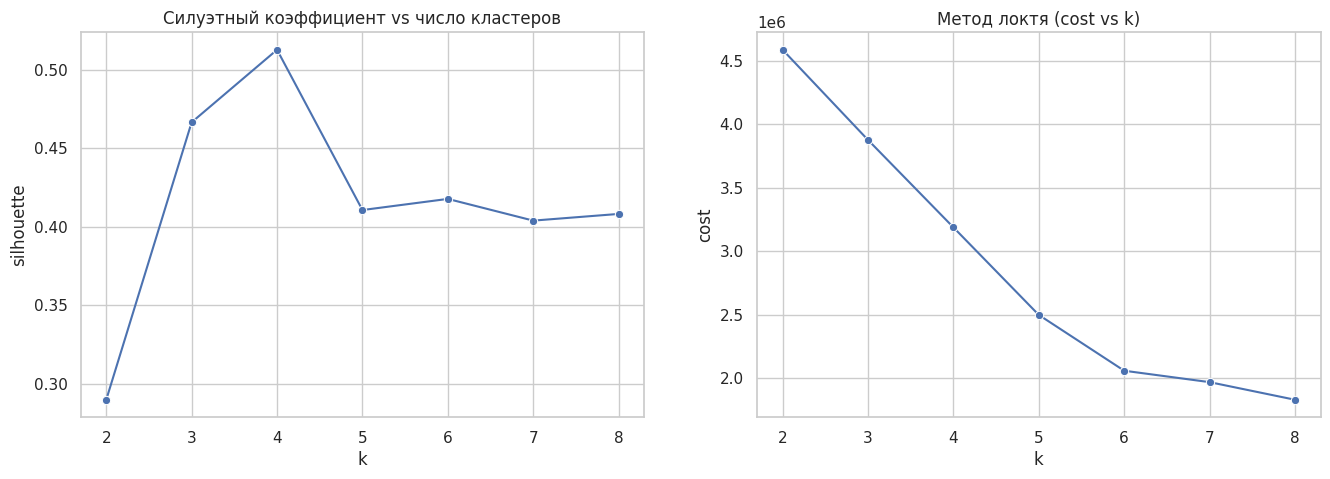

In [8]:
# Переводим результаты в pandas для графика
k_results_df = pd.DataFrame(k_results)

# Две фигуры рядом
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Силуэт в зависимости от k
sns.lineplot(data=k_results_df, x="k", y="silhouette", marker="o", ax=axes[0])
axes[0].set_title("Силуэтный коэффициент vs число кластеров")

# Метод локтя: стоимость vs k
sns.lineplot(data=k_results_df, x="k", y="cost", marker="o", ax=axes[1])
axes[1].set_title("Метод локтя (cost vs k)")
plt.show()

In [9]:
# Лучшее k - то, где силуэт максимальный
best_k = int(k_results_df.loc[k_results_df["silhouette"].idxmax(), "k"])
print(f"Лучшее k по силуэту: {best_k}")

# Финальная модель KMeans с лучшим k
kmeans_model = KMeans(k=best_k, seed=42, featuresCol="scaled_features").fit(scaled_df)

# Назначаем кластеры всем строкам
clustered_df = kmeans_model.transform(scaled_df)

Лучшее k по силуэту: 4


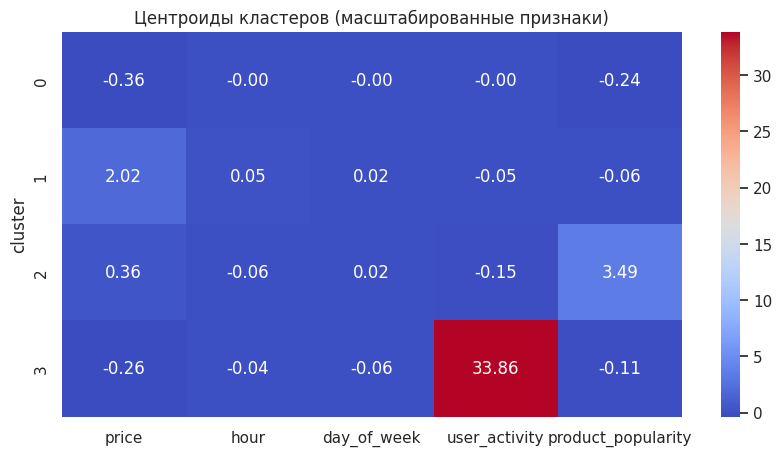

In [10]:
# Центроиды кластеров в масштабированном пространстве (список numpy-массивов)
centroids = kmeans_model.clusterCenters()

# Переводим в таблицу: строки - кластеры, столбцы - признаки
centroids_df = pd.DataFrame(centroids, columns=feature_columns)
centroids_df.index.name = "cluster"

# Тепловая карта центроидов
plt.figure(figsize=(10, 5))
sns.heatmap(centroids_df, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Центроиды кластеров (масштабированные признаки)")
plt.show()

In [11]:
# Средние значения исходных признаков по кластерам - для интерпретации
cluster_profile = clustered_df.groupBy("prediction").avg(*feature_columns).orderBy("prediction")

# Показываем профиль кластеров
cluster_profile.show(truncate=False)

# Размеры кластеров (маленькая таблица - можно на драйвер)
clustered_df.groupBy("prediction").count().orderBy("prediction").toPandas()

+----------+------------------+------------------+------------------+------------------+-----------------------+
|prediction|avg(price)        |avg(hour)         |avg(day_of_week)  |avg(user_activity)|avg(product_popularity)|
+----------+------------------+------------------+------------------+------------------+-----------------------+
|0         |161.9709023944018 |11.237449253194788|4.1496346687976695|157.2549040934039 |34527.80206742427      |
|1         |894.8670314368316 |11.499210833783147|4.1924813982248885|135.61387566020073|71904.12545351435      |
|2         |383.04541545501905|10.944542435365719|4.190303665919817 |88.29162098171012 |792828.6715291351      |
|3         |193.40178036605658|11.043261231281198|4.036605657237937 |16470.820299500832|61204.11314475873      |
+----------+------------------+------------------+------------------+------------------+-----------------------+



,prediction,count
0,0,873454
1,1,146357
2,2,62931
3,3,601


## Визуализация кластеров через PCA

Снижаем 5 признаков до 2 главных компонент и рисуем точки, окрашенные по кластеру.

26/11/05 19:00:30 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.lapack.JNILAPACK


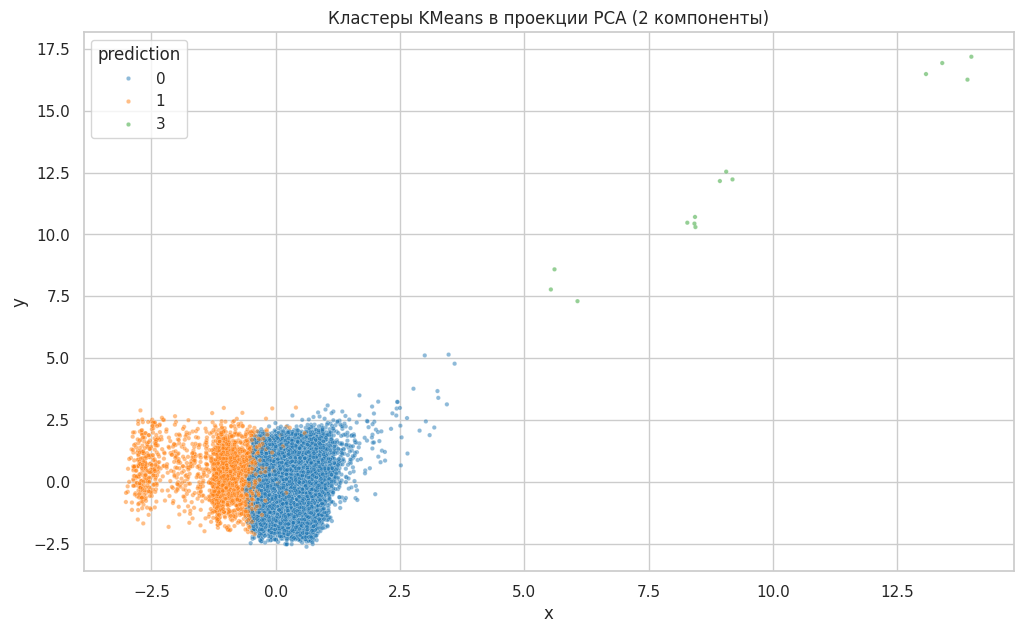

In [12]:
# PCA до 2 компонент - только для визуализации
pca_model = PCA(k=2, inputCol="scaled_features", outputCol="pca_features").fit(scaled_df)

# Применяем PCA к данным с кластерами
pca_df = pca_model.transform(clustered_df)

# Случайные 20000 строк для графика (больше не нужно)
pca_sample = pca_df.select("pca_features", "prediction").sample(fraction=0.3, seed=42).limit(20000)

# Разбираем вектор pca_features на отдельные столбцы x и y и выгружаем в pandas
pca_pandas = (pca_sample
              .withColumn("x", vector_to_array("pca_features").getItem(0))
              .withColumn("y", vector_to_array("pca_features").getItem(1))
              .select("x", "y", "prediction").toPandas())

# Диаграмма рассеяния, цвет - номер кластера
plt.figure(figsize=(12, 7))
sns.scatterplot(data=pca_pandas, x="x", y="y", hue="prediction", palette="tab10", s=10, alpha=0.5)
plt.title("Кластеры KMeans в проекции PCA (2 компоненты)")
plt.show()

## DBSCAN

В Spark MLlib нет DBSCAN, поэтому берем небольшую выборку (5000 строк) в pandas и применяем DBSCAN из sklearn. Ключевой параметр - eps (радиус соседства).

In [13]:
# Небольшая выборка масштабированных признаков: 5000 строк на драйвер
dbscan_sample = scaled_df.select("scaled_features").limit(5000)

# Разбираем вектор в numpy-массив размером (5000 x 5) для sklearn
dbscan_vectors = np.array([row["scaled_features"].toArray() for row in dbscan_sample.collect()])

# Проверяем форму массива
print(f"Форма массива: {dbscan_vectors.shape}")

Форма массива: (5000, 5)


In [14]:
# Пробуем несколько значений eps и фиксируем метрики
dbscan_results = []

# Перебираем радиус соседства eps
for eps in [0.3, 0.5, 0.7, 1.0]:
    # min_samples - минимум точек в окрестности, чтобы точка считалась "ядровой"
    labels = DBSCAN(eps=eps, min_samples=10).fit_predict(dbscan_vectors)
    # Число кластеров: метка -1 это шум, не кластер
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    # Доля точек-шума
    noise_share = (labels == -1).mean()
    # Силуэт считаем только если кластеров больше одного (иначе он не определен)
    sil = silhouette_score(dbscan_vectors, labels) if n_clusters > 1 else float("nan")
    dbscan_results.append({"eps": eps, "clusters": n_clusters,
                           "noise_share": noise_share, "silhouette": sil})
    # Печатаем прогресс
    print(f"eps = {eps}: кластеров = {n_clusters}, шум = {noise_share:.1%}, silhouette = {sil:.3f}")

eps = 0.3: кластеров = 34, шум = 22.8%, silhouette = -0.121
eps = 0.5: кластеров = 4, шум = 5.3%, silhouette = -0.057
eps = 0.7: кластеров = 2, шум = 1.9%, silhouette = 0.067
eps = 1.0: кластеров = 1, шум = 0.9%, silhouette = nan


In [15]:
# Таблица результатов DBSCAN
dbscan_results_df = pd.DataFrame(dbscan_results)

# Показываем таблицу
dbscan_results_df

,eps,clusters,noise_share,silhouette
0,0.3,34,0.2276,-0.121151
1,0.5,4,0.0526,-0.057115
2,0.7,2,0.0188,0.067258
3,1.0,1,0.0090,NaN


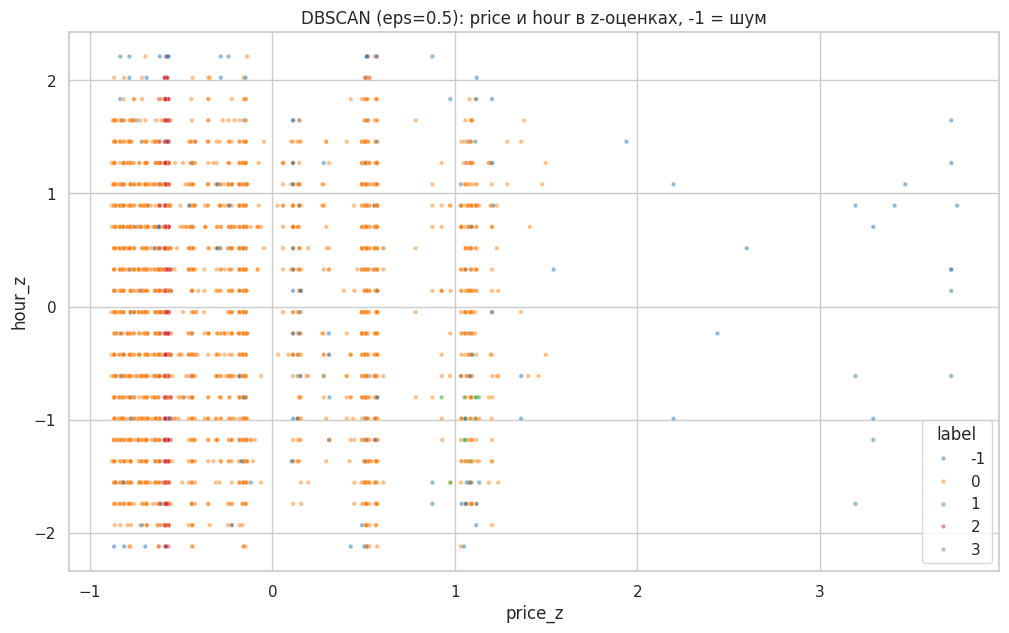

In [16]:
# Визуализируем DBSCAN с eps=0.5 (компромисс: не один кластер, шум умеренный)
labels_best = DBSCAN(eps=0.5, min_samples=10).fit_predict(dbscan_vectors)

# Рисуем по первым двум масштабированным признакам (price и hour)
dbscan_pandas = pd.DataFrame(dbscan_vectors[:, :2], columns=["price_z", "hour_z"])
dbscan_pandas["label"] = labels_best

# Шум (-1) попадет в легенду как отдельная метка, кластеры - цветами
plt.figure(figsize=(12, 7))
sns.scatterplot(data=dbscan_pandas, x="price_z", y="hour_z", hue="label", palette="tab10", s=10, alpha=0.5)
plt.title("DBSCAN (eps=0.5): price и hour в z-оценках, -1 = шум")
plt.show()

## Сравнение и выводы

- **KMeans** делит данные на заданное число сферических кластеров; оптимальное k ищем по силуэту и методу локтя.
- **DBSCAN** находит кластеры произвольной формы и помечает выбросы как шум; результат сильно зависит от eps.

Метрики зафиксированы выше: силуэт KMeans для всех k, стоимость (метод локтя), для DBSCAN - силуэт, число кластеров и доля шума.

In [17]:
# Итоговая сводка метрик: KMeans и DBSCAN рядом
print("KMeans:")
print(k_results_df.to_string(index=False))
print()
print("DBSCAN:")
print(dbscan_results_df.to_string(index=False))

KMeans:
 k  silhouette         cost
 2    0.289721 4.584947e+06
 3    0.466585 3.874668e+06
 4    0.512836 3.186293e+06
 5    0.410656 2.496736e+06
 6    0.417751 2.057378e+06
 7    0.403911 1.967510e+06
 8    0.408177 1.828842e+06

DBSCAN:
 eps  clusters  noise_share  silhouette
 0.3        34       0.2276   -0.121151
 0.5         4       0.0526   -0.057115
 0.7         2       0.0188    0.067258
 1.0         1       0.0090         NaN


In [18]:
# Останавливаем Spark-сессию, освобождая ресурсы кластера
spark.stop()